# Data Exploration Report — Gecombineerd Dashboard BP3

Dit notebook bevat een **data exploration report** voor de data die wordt gebruikt in het gecombineerde dashboard: IC-data, heupvervangingsoperaties en een wachttijden-benchmark tegenover regionale ziekenhuizen.

De data bestaat uit:
- **EPD-data** (`bp3/data/*_combined.csv`): patiëntgegevens, episodes of care (EOC), behandelingen, anesthesie en patiëntstatistieken, als één samengevoegde dataset voor het data warehouse van het ziekenhuis.
- **IC-machinedata** (`bp3/data/machine_data/*.csv`): time-series metingen van vitale parameters, alleen beschikbaar voor patiënten met een koppeling in `patient_machine_mapping.csv`.
- **Vragenlijstdata** (`bp3/data/questionnaires/*.resp`): patiëntgerapporteerde uitkomsten (patient-reported outcomes) na een heupoperatie, alleen beschikbaar voor een deel van de patiënten.
- **NZa-wachttijdendata** (`bp3/scripts/nza wachttijden/`): een live API-snapshot en een historisch bulkbestand van wachttijden, gebruikt om de wachttijd van het eigen ziekenhuis (Radboudumc) te vergelijken met ziekenhuizen in de regio.

De requirements staan beschreven in `bp3/doc/requirements.md`.


In [1]:
import json
import os

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

# ── Paden naar de data-directories ───────────────────────────────────────────
# Het notebook staat in bp3/notebooks/; de data staat in bp3/data/ en bp3/scripts/
NOTEBOOK_DIR = os.path.dirname(os.path.abspath("__file__"))
BP3_DIR = os.path.join(NOTEBOOK_DIR, "..")
DATA_DIR = os.path.join(BP3_DIR, "data")
MACHINE_DIR = os.path.join(DATA_DIR, "machine_data")
QUEST_DIR = os.path.join(DATA_DIR, "questionnaires")
SCRIPTS_DIR = os.path.join(BP3_DIR, "scripts")
NZA_DIR = os.path.join(SCRIPTS_DIR, "nza wachttijden")

print("Data-directory:      ", os.path.abspath(DATA_DIR))
print("Machine-directory:   ", os.path.abspath(MACHINE_DIR))
print("Questionnaire-dir.:  ", os.path.abspath(QUEST_DIR))
print("NZa wachttijden-dir.:", os.path.abspath(NZA_DIR))


Data-directory:       /workspaces/Data-Engineer/bp3/data
Machine-directory:    /workspaces/Data-Engineer/bp3/data/machine_data
Questionnaire-dir.:   /workspaces/Data-Engineer/bp3/data/questionnaires
NZa wachttijden-dir.: /workspaces/Data-Engineer/bp3/scripts/nza wachttijden


## 1. EPD-data inladen en NaN-overzicht

De EPD-data (`bp3/data/*_combined.csv`) wordt ingeladen. De negen tabellen komen overeen met de tabellen in `ddl_epd_bp3.sql`. Per tabel wordt gecontroleerd hoeveel records aanwezig zijn en hoeveel NOT NULL-kolommen (zoals gedefinieerd in de DDL) toch een NaN-waarde bevatten.

In [2]:
# ── Inladen van alle EPD-tabellen (combined-bestanden) ───────────────────────

patient = pd.read_csv(os.path.join(DATA_DIR, "patient_combined.csv"), parse_dates=["dob"])

patient_statistic_type = pd.read_csv(os.path.join(DATA_DIR, "patient_statistic_type_combined.csv"))

patient_observation = pd.read_csv(
    os.path.join(DATA_DIR, "patient_observation_combined.csv"), parse_dates=["note_ts"]
)

patient_statistic = pd.read_csv(
    os.path.join(DATA_DIR, "patient_statistic_combined.csv"), parse_dates=["stat_ts"]
)

treatment_type = pd.read_csv(os.path.join(DATA_DIR, "treatment_type_combined.csv"))

eoc = pd.read_csv(
    os.path.join(DATA_DIR, "eoc_combined.csv"), parse_dates=["intake_date", "discharge_date"]
)

eoc_treatment = pd.read_csv(
    os.path.join(DATA_DIR, "eoc_treatment_combined.csv"), parse_dates=["eoc_time"]
)
# is_primary is opgeslagen als integer (0/1); omzetten naar bool
eoc_treatment["is_primary"] = eoc_treatment["is_primary"].astype(bool)

eoc_treatment_anesthesia = pd.read_csv(
    os.path.join(DATA_DIR, "eoc_treatment_anesthesia_combined.csv"),
    parse_dates=["anesthesia_time"],
)

hip_treatment_position = pd.read_csv(
    os.path.join(DATA_DIR, "hip_treatment_position_combined.csv"),
    parse_dates=["position_time"],
)

# ── NOT NULL-kolommen per tabel, afgeleid uit ddl_epd_bp3.sql ────────────
not_null_cols = {
    "patient":                    ["pid", "firstname", "lastname"],
    "patient_statistic_type":     ["stid", "stname", "sttype"],
    "patient_observation":        ["poid", "pid", "note_ts", "note_text", "pain_score"],
    "patient_statistic":          ["pid", "stid"],
    "treatment_type":             ["tid", "tname"],
    "eoc":                        ["eocid", "pid", "intake_date"],
    "eoc_treatment":              ["eocid", "tid", "is_primary", "eoc_time"],
    "eoc_treatment_anesthesia":   ["eocid", "anesthesia_type", "anesthesia_time"],
    "hip_treatment_position":     ["eocid", "position_type", "position_time"],
}

tables = {
    "patient":                  patient,
    "patient_statistic_type":   patient_statistic_type,
    "patient_observation":      patient_observation,
    "patient_statistic":        patient_statistic,
    "treatment_type":           treatment_type,
    "eoc":                      eoc,
    "eoc_treatment":            eoc_treatment,
    "eoc_treatment_anesthesia": eoc_treatment_anesthesia,
    "hip_treatment_position":   hip_treatment_position,
}

# ── Overzichtstabel: records en NaN's in NOT NULL-kolommen ───────────────────
rows = []
for naam, df in tables.items():
    nan_in_notnull = sum(df[col].isna().sum() for col in not_null_cols[naam])
    rows.append({"Tabel": naam, "Records": len(df), "NaN in NOT NULL-kolommen": nan_in_notnull})

overzicht = pd.DataFrame(rows).set_index("Tabel")
print(overzicht.to_string())

# ── Referentiële integriteit en dubbele primary keys ─────────────────────────
orphan_eoc = eoc_treatment[~eoc_treatment["eocid"].isin(eoc["eocid"])]
orphan_tid = eoc_treatment[~eoc_treatment["tid"].isin(treatment_type["tid"])]
dubbele_pid = patient["pid"].duplicated().sum()
dubbele_eocid = eoc["eocid"].duplicated().sum()

print("\n=== Referentiële integriteit en dubbele primary keys ===")
print(f"eoc_treatment-rijen met een eocid die niet in eoc voorkomt      : {len(orphan_eoc)}")
print(f"eoc_treatment-rijen met een tid die niet in treatment_type voorkomt: {len(orphan_tid)}")
print(f"Dubbele pid's in patient                                        : {dubbele_pid}")
print(f"Dubbele eocid's in eoc                                          : {dubbele_eocid}")
if len(orphan_eoc) == 0 and len(orphan_tid) == 0 and dubbele_pid == 0 and dubbele_eocid == 0:
    print("Geen problemen gevonden.")


                          Records  NaN in NOT NULL-kolommen
Tabel                                                      
patient                     13006                         0
patient_statistic_type          3                         0
patient_observation         15539                         0
patient_statistic           39018                         0
treatment_type                 35                         0
eoc                         13006                         0
eoc_treatment               14100                         0
eoc_treatment_anesthesia    11188                         0
hip_treatment_position       4077                         0

=== Referentiële integriteit en dubbele primary keys ===
eoc_treatment-rijen met een eocid die niet in eoc voorkomt      : 0
eoc_treatment-rijen met een tid die niet in treatment_type voorkomt: 0
Dubbele pid's in patient                                        : 0
Dubbele eocid's in eoc                                          : 0
Geen pr

## 2. Patiëntdemografie

Demografische kenmerken van de volledige, gecombineerde patiëntpopulatie (`patient`-tabel en patiëntstatistieken: BMI, ASA-klasse, rookstatus).

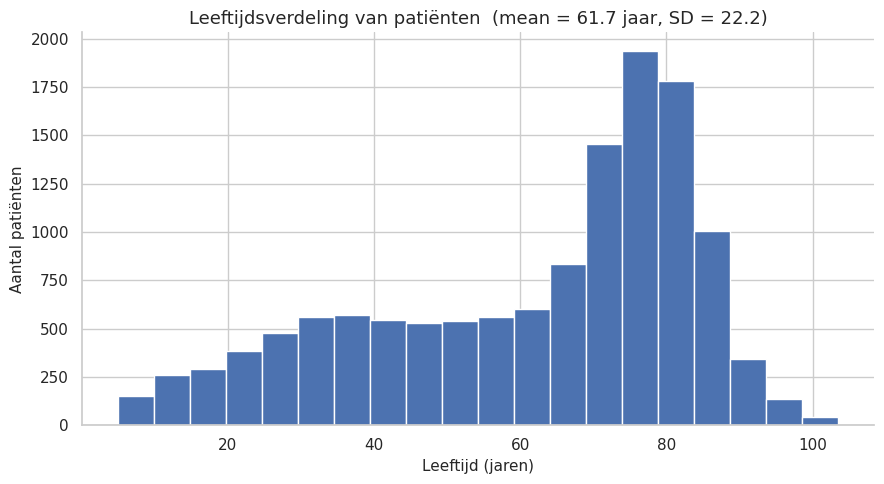

In [3]:
# ── Leeftijdsverdeling ────────────────────────────────────────────────────────

# Bereken leeftijd in jaren op basis van geboortedatum
patient["leeftijd"] = (pd.Timestamp.today() - patient["dob"]).dt.days / 365.25

leeftijd = patient["leeftijd"].dropna()
mu, sigma = leeftijd.mean(), leeftijd.std()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(leeftijd, bins=20, color="#4C72B0", edgecolor="white")
ax.set_title(f"Leeftijdsverdeling van patiënten  (mean = {mu:.1f} jaar, SD = {sigma:.1f})")
ax.set_xlabel("Leeftijd (jaren)")
ax.set_ylabel("Aantal patiënten")
plt.tight_layout()
plt.show()


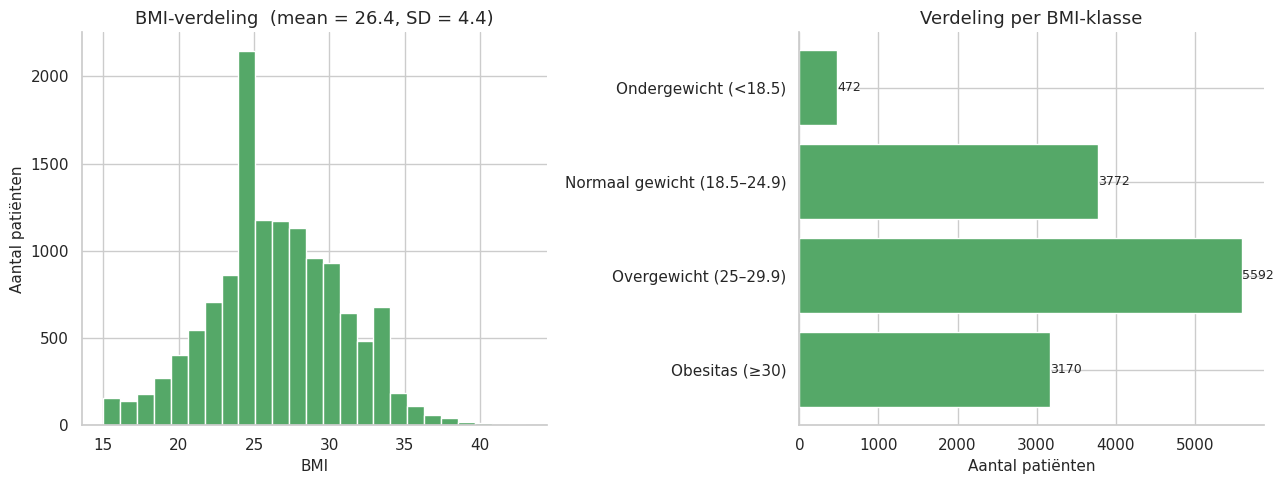

In [4]:
# ── BMI-verdeling: histogram en verdeling per BMI-klasse ─────────────────────

# Haal BMI-waarden op uit patient_statistic (stid = 1 = bmi)
bmi = (
    patient_statistic[patient_statistic["stid"] == 1][["pid", "stvalue_int"]]
    .rename(columns={"stvalue_int": "bmi"})
)

# BMI-klassen conform de gangbare klinische indeling (zie requirements.md):
# ondergewicht, normaal gewicht, overgewicht, obesitas.
bmi_bins = [0, 18.5, 25, 30, float("inf")]
bmi_labels = [
    "Ondergewicht (<18.5)",
    "Normaal gewicht (18.5–24.9)",
    "Overgewicht (25–29.9)",
    "Obesitas (≥30)",
]
bmi["bmi_klasse"] = pd.cut(bmi["bmi"], bins=bmi_bins, labels=bmi_labels, right=False)

bmi_vals = bmi["bmi"].dropna()
mu_bmi, sigma_bmi = bmi_vals.mean(), bmi_vals.std()
bmi_counts = bmi["bmi_klasse"].value_counts().reindex(bmi_labels)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Links: histogram van ruwe BMI-waarden
axes[0].hist(bmi_vals, bins=25, color="#55A868", edgecolor="white")
axes[0].set_title(f"BMI-verdeling  (mean = {mu_bmi:.1f}, SD = {sigma_bmi:.1f})")
axes[0].set_xlabel("BMI")
axes[0].set_ylabel("Aantal patiënten")

# Rechts: horizontaal staafdiagram per BMI-klasse
axes[1].barh(bmi_counts.index, bmi_counts.values, color="#55A868", edgecolor="white")
axes[1].set_title("Verdeling per BMI-klasse")
axes[1].set_xlabel("Aantal patiënten")
axes[1].invert_yaxis()  # grootste groep bovenaan
for i, v in enumerate(bmi_counts.values):
    axes[1].text(v + 5, i, str(v), va="center", fontsize=9)

plt.tight_layout()
plt.show()


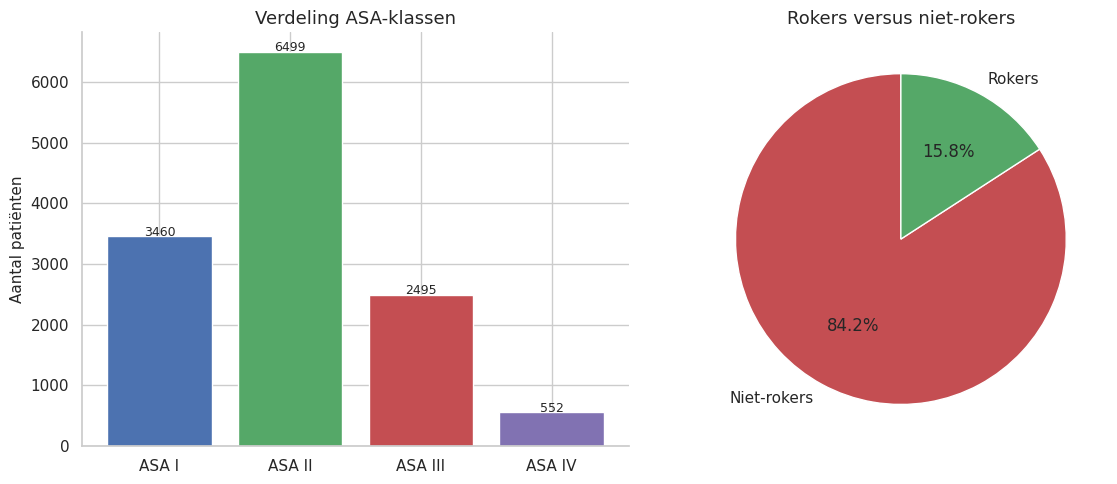

In [5]:
# ── ASA-klasse en rookstatus ──────────────────────────────────────────────────

# ASA-scores ophalen (stid = 3) en vertalen naar compacte klasse-labels
asa_raw = (
    patient_statistic[patient_statistic["stid"] == 3][["pid", "stvalue_string"]]
    .rename(columns={"stvalue_string": "asa_omschrijving"})
)
asa_map = {
    "healthy":
        "ASA I",
    "mild to moderate systemic abnormality that does not result in functional impairment":
        "ASA II",
    "Severe functionally limiting systemic abnormality":
        "ASA III",
    "systemic abnormality that poses a constant life-threatening danger":
        "ASA IV",
}
asa_raw["asa_klasse"] = asa_raw["asa_omschrijving"].map(asa_map)
asa_order = ["ASA I", "ASA II", "ASA III", "ASA IV"]
asa_counts = asa_raw["asa_klasse"].value_counts().reindex(asa_order)

# Rookstatus (stid = 2)
smoking_raw = (
    patient_statistic[patient_statistic["stid"] == 2][["pid", "stvalue_bool"]]
    .rename(columns={"stvalue_bool": "roker"})
)
smoking_raw["roker"] = smoking_raw["roker"].map({1.0: "Rokers", 0.0: "Niet-rokers"})
smoking_counts = smoking_raw["roker"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Links: staafdiagram ASA-klassen
axes[0].bar(asa_counts.index, asa_counts.values,
            color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"], edgecolor="white")
axes[0].set_title("Verdeling ASA-klassen")
axes[0].set_ylabel("Aantal patiënten")
for i, v in enumerate(asa_counts.values):
    axes[0].text(i, v + 10, str(v), ha="center", fontsize=9)

# Rechts: taartdiagram rookstatus
axes[1].pie(
    smoking_counts.values,
    labels=smoking_counts.index,
    autopct="%1.1f%%",
    colors=["#C44E52", "#55A868"],
    startangle=90,
)
axes[1].set_title("Rokers versus niet-rokers")

plt.tight_layout()
plt.show()


## 3. Groei en diversificatie van de dataset over tijd

Deze sectie laat zien hoe de gecombineerde dataset (`eoc` en `eoc_treatment`) is gegroeid over de jaren 2016–2026, en hoe de behandelingen zijn gediversifieerd: niet langer alleen heupoperaties, maar veel verschillende behandeltypen.

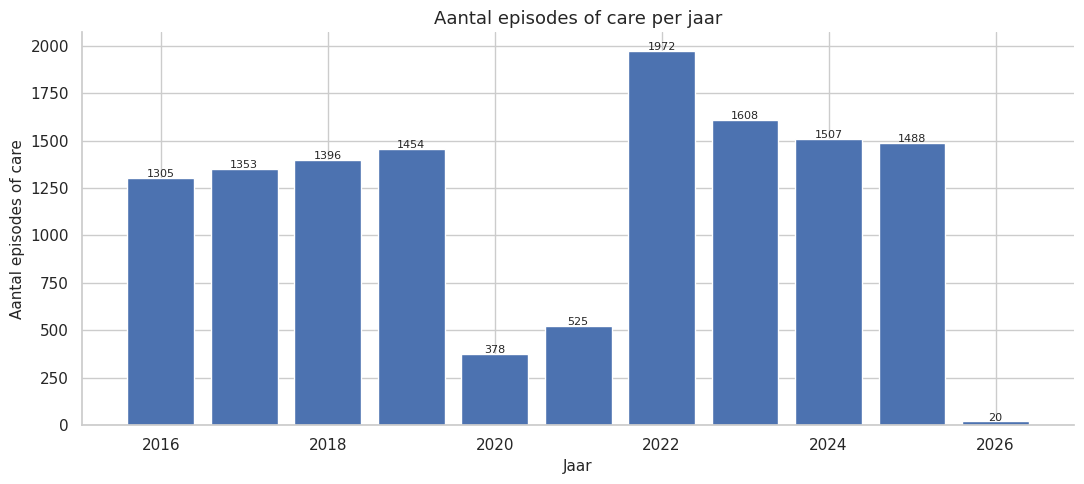

jaar
2016    1305
2017    1353
2018    1396
2019    1454
2020     378
2021     525
2022    1972
2023    1608
2024    1507
2025    1488
2026      20


In [6]:
# ── Aantal episodes of care per jaar (2016–2026) ─────────────────────────────

eoc["jaar"] = eoc["intake_date"].dt.year
eoc_per_jaar = eoc.groupby("jaar").size().reindex(range(2016, 2027), fill_value=0)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(eoc_per_jaar.index, eoc_per_jaar.values, color="#4C72B0", edgecolor="white")
ax.set_title("Aantal episodes of care per jaar")
ax.set_xlabel("Jaar")
ax.set_ylabel("Aantal episodes of care")
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
for jaar, v in eoc_per_jaar.items():
    ax.text(jaar, v + 5, str(v), ha="center", fontsize=8)
plt.tight_layout()
plt.show()

print(eoc_per_jaar.to_string())


De grafiek toont een duidelijke **dip in 2020–2021** en een **piek in 2022**. 2026 bevat geen volledig jaar aan data omdat de dataset op de huidige datum ophoudt.

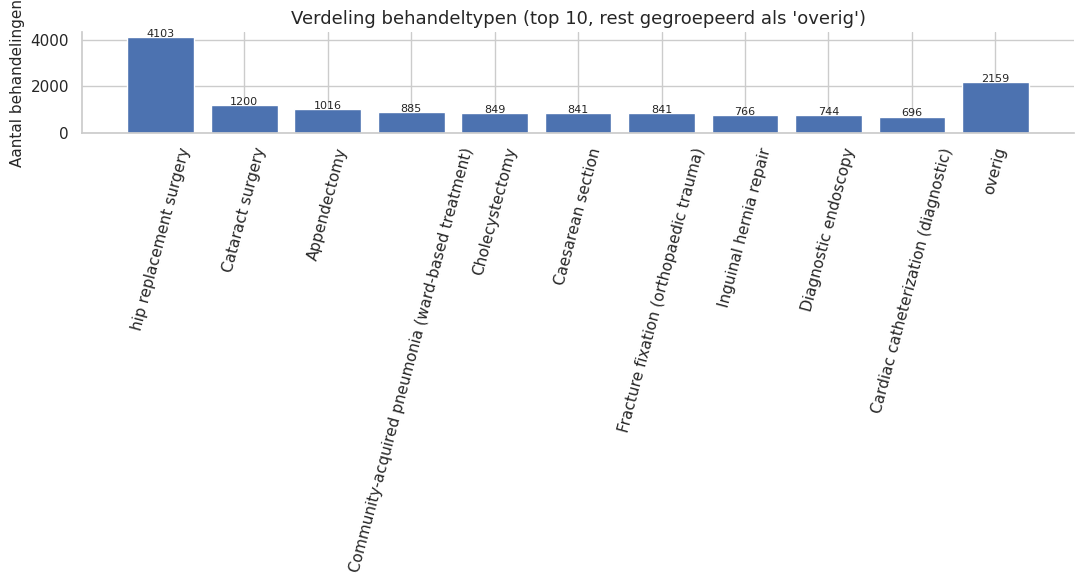

Aantal distincte behandeltypen in de dataset: 35

Episodes of care met meer dan één behandeling: 1058 / 13006 (8.1%)


In [7]:
# ── Verdeling van behandeltypen (top N, rest gegroepeerd als "overig") ───────

treat = eoc_treatment.merge(treatment_type, on="tid", how="left")
tname_counts = treat["tname"].value_counts()

TOP_N = 10
top_treatments = tname_counts.head(TOP_N)
overig_totaal = tname_counts.iloc[TOP_N:].sum()

plot_counts = top_treatments.copy()
if overig_totaal > 0:
    plot_counts["overig"] = overig_totaal

fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(plot_counts.index, plot_counts.values, color="#4C72B0", edgecolor="white")
ax.set_title(f"Verdeling behandeltypen (top {TOP_N}, rest gegroepeerd als 'overig')")
ax.set_ylabel("Aantal behandelingen")
ax.tick_params(axis="x", rotation=75)
for i, v in enumerate(plot_counts.values):
    ax.text(i, v + 5, str(v), ha="center", fontsize=8)
plt.tight_layout()
plt.show()

print(f"Aantal distincte behandeltypen in de dataset: {tname_counts.shape[0]}")

# ── Aandeel episodes of care met meer dan één behandeling ────────────────────
# Dit betreft de volledige dataset (niet alleen de heupvervanging-groep uit sectie 4).
n_behandelingen_per_eoc = eoc_treatment.groupby("eocid").size()
aandeel_meerdere = (n_behandelingen_per_eoc > 1).sum()
print(f"\nEpisodes of care met meer dan één behandeling: {aandeel_meerdere} / {len(n_behandelingen_per_eoc)} "
      f"({aandeel_meerdere / len(n_behandelingen_per_eoc) * 100:.1f}%)")


## 4. Heupoperatie-karakteristieken

Deze sectie is beperkt tot episodes of care met een behandeling uit de **heupvervanging-groep** (hip replacement surgery, arthrotomy, revision (partial), revision (complete), reposition) — zie `bp3/doc/requirements.md`. Andere behandelingen (bijv. IC-behandelingen of de nieuwe, diverse behandelingen) vallen buiten deze sectie.

Een reïnterventie is een niet-primaire behandeling uit deze groep (arthrotomy, revision (partial), revision (complete), reposition) binnen dezelfde episode of care als een primaire heupoperatie.

Episodes of care met een behandeling uit de heupvervanging-groep: 4407


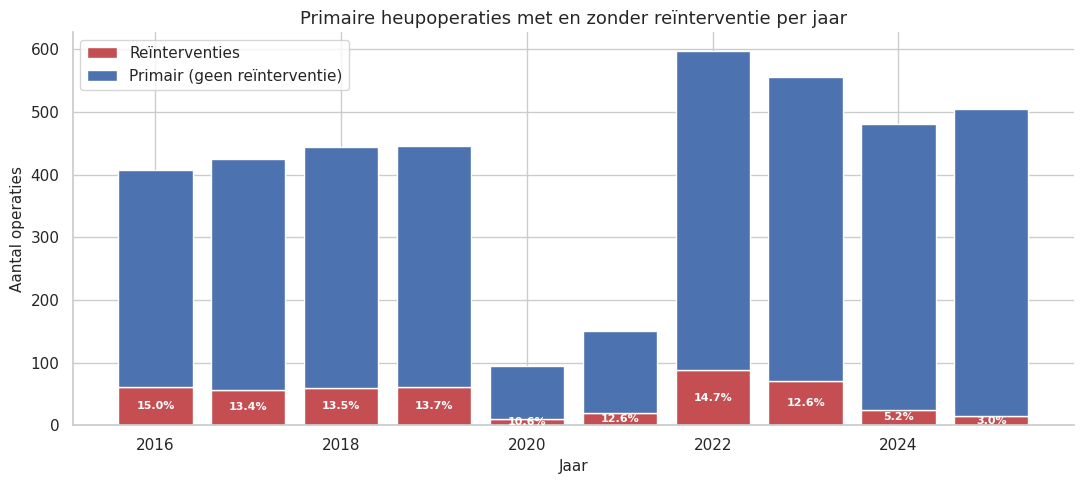

In [8]:
# ── Scope: alleen EOC's met een behandeling uit de heupvervanging-groep ──────

HIP_GROUP = [
    "hip replacement surgery", "arthrotomy",
    "revision (partial)", "revision (complete)", "reposition",
]
PRIMAIR = "hip replacement surgery"
REINT_NAMEN = ["arthrotomy", "revision (partial)", "revision (complete)", "reposition"]

# Voeg behandelingsnaam en opnamejaar toe, en filter direct op de heupvervanging-groep
treat_all = eoc_treatment.merge(treatment_type, on="tid", how="left")
treat_all = treat_all.merge(eoc[["eocid", "pid", "intake_date"]], on="eocid", how="left")
treat_all["jaar"] = treat_all["intake_date"].dt.year

hip_eocids = set(treat_all.loc[treat_all["tname"].isin(HIP_GROUP), "eocid"])
treat = treat_all[treat_all["eocid"].isin(hip_eocids)].copy()

print(f"Episodes of care met een behandeling uit de heupvervanging-groep: {len(hip_eocids)}")

# EOC's met een primaire heupoperatie
primaire_eoc = treat[treat["tname"] == PRIMAIR][["eocid", "jaar"]].drop_duplicates()

# EOC's die ook een reïnterventie hebben
reint_eoc = treat[treat["tname"].isin(REINT_NAMEN)][["eocid"]].drop_duplicates()
reint_eoc_set = set(reint_eoc["eocid"])

# Samenvatting per jaar: totaal primair en aantal met reïnterventie
primair_per_jaar = primaire_eoc.groupby("jaar").size().rename("primair")
reint_per_jaar = (
    primaire_eoc[primaire_eoc["eocid"].isin(reint_eoc_set)]
    .groupby("jaar").size()
    .rename("reinterventie")
)

samenvatting = pd.concat([primair_per_jaar, reint_per_jaar], axis=1).fillna(0).astype(int)
samenvatting["pct"] = (samenvatting["reinterventie"] / samenvatting["primair"] * 100).round(1)

# ── Gestapeld staafdiagram: % reïnterventies per jaar ────────────────────────
# Onderste segment = reïnterventies; de hele balk = aantal primaire operaties.
fig, ax = plt.subplots(figsize=(11, 5))
jaren = samenvatting.index
geen_reint = samenvatting["primair"] - samenvatting["reinterventie"]

ax.bar(jaren, samenvatting["reinterventie"],
       label="Reïnterventies", color="#C44E52", edgecolor="white")
ax.bar(jaren, geen_reint, bottom=samenvatting["reinterventie"],
       label="Primair (geen reïnterventie)", color="#4C72B0", edgecolor="white")

for jaar in jaren:
    reint = samenvatting.loc[jaar, "reinterventie"]
    pct = samenvatting.loc[jaar, "pct"]
    if reint > 0:
        ax.text(jaar, reint / 2, f"{pct}%",
                ha="center", va="center", color="white", fontsize=8, fontweight="bold")

ax.set_title("Primaire heupoperaties met en zonder reïnterventie per jaar")
ax.set_xlabel("Jaar")
ax.set_ylabel("Aantal operaties")
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.legend()
plt.tight_layout()
plt.show()


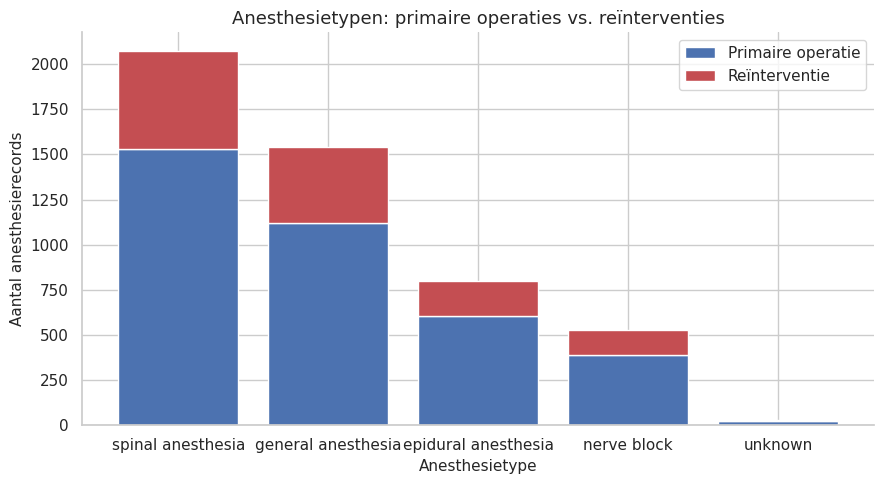

In [9]:
# ── Anesthesietypen: gestapeld staafdiagram, gesplitst naar primair/reïnterventie ─
# Eén balk per anesthesietype; elke balk is gesplitst in "primaire operatie" en
# "reïnterventie", op basis van of het EOC bij die anesthesietoediening een
# reïnterventie bevat.

eta = eoc_treatment_anesthesia[eoc_treatment_anesthesia["eocid"].isin(hip_eocids)].copy()
eta["categorie"] = eta["eocid"].isin(reint_eoc_set).map(
    {False: "Primaire operatie", True: "Reïnterventie"}
)

anest_pivot = (
    eta.groupby(["anesthesia_type", "categorie"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Primaire operatie", "Reïnterventie"], fill_value=0)
)
anest_pivot = anest_pivot.loc[anest_pivot.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 5))
bottom = np.zeros(len(anest_pivot))
for kolom, kleur in zip(anest_pivot.columns, ["#4C72B0", "#C44E52"]):
    vals = anest_pivot[kolom].values
    ax.bar(anest_pivot.index, vals, bottom=bottom, label=kolom, color=kleur, edgecolor="white")
    bottom += vals

ax.set_title("Anesthesietypen: primaire operaties vs. reïnterventies")
ax.set_xlabel("Anesthesietype")
ax.set_ylabel("Aantal anesthesierecords")
ax.legend()
plt.tight_layout()
plt.show()


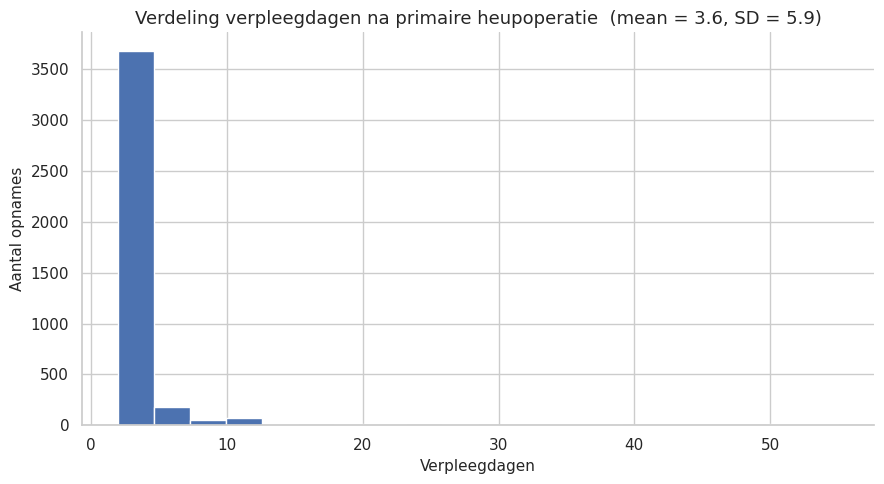

In [10]:
# ── Verpleegdagen na de primaire heupoperatie ────────────────────────────────

primaire_eocids = set(primaire_eoc["eocid"])
eoc_primair = eoc[eoc["eocid"].isin(primaire_eocids)].copy()
eoc_primair["verpleegdagen"] = (eoc_primair["discharge_date"] - eoc_primair["intake_date"]).dt.days

los = eoc_primair["verpleegdagen"].dropna()
mu_los, sigma_los = los.mean(), los.std()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(los, bins=20, color="#4C72B0", edgecolor="white")
ax.set_title(f"Verdeling verpleegdagen na primaire heupoperatie  (mean = {mu_los:.1f}, SD = {sigma_los:.1f})")
ax.set_xlabel("Verpleegdagen")
ax.set_ylabel("Aantal opnames")
plt.tight_layout()
plt.show()


## 5. Vragenlijstdata

De vragenlijstdata (`bp3/data/questionnaires/<pid>.resp`) is alleen beschikbaar voor een deel van de patiënten (zie `bp3/doc/requirements.md`). Elk bestand bevat scores op de categorieën pijn, mobiliteit en tevredenheid, gemeten 3 en 12 maanden na de interventie.

In [11]:
# ── Inlezen van alle .resp vragenlijstbestanden ──────────────────────────────

# Patiënten met IC-machinedata krijgen geen vragenlijst. De vragenlijst-cohort
# bestaat uit de patiënten met een pid onder de laagste pid die machinedata heeft.
machine_mapping_pids = pd.read_csv(os.path.join(DATA_DIR, "patient_machine_mapping.csv"))["PID"]
VRAGENLIJST_PID_GRENS = machine_mapping_pids.str.lstrip("P").astype(int).min()


def parse_resp_file(filepath: str, pid: int) -> dict:
    """
    Lees één .resp-bestand in en retourneer een dictionary met de pid
    en alle sleutel-waarde-paren als numerieke waarden.
    """
    record = {"pid": pid}
    with open(filepath, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if ":" not in line:
                continue
            key, value = line.split(":", 1)
            try:
                record[key.strip()] = float(value.strip())
            except ValueError:
                pass
    return record


records = []
for fname in os.listdir(QUEST_DIR):
    if not fname.endswith(".resp"):
        continue
    pid_val = int(fname.replace(".resp", ""))
    records.append(parse_resp_file(os.path.join(QUEST_DIR, fname), pid_val))

questionnaire = pd.DataFrame(records).rename(columns={
    "Dagelijks functioneren na 3 maanden":  "mobiliteit_3m",
    "Dagelijks functioneren na 12 maanden": "mobiliteit_12m",
    "Tevredenheid resultaat na 3 maanden":  "tevredenheid_3m",
    "Tevredenheid resultaat na 12 maanden": "tevredenheid_12m",
    "Verandering in pijn na 3 maanden":     "pijn_3m",
    "Verandering in pijn na 12 maanden":    "pijn_12m",
})

print(f"Aantal ingelezen vragenlijsten: {len(questionnaire)}")
print(f"Alle bestanden hebben een pid onder de vragenlijst-grens ({VRAGENLIJST_PID_GRENS}): "
      f"{(questionnaire['pid'] < VRAGENLIJST_PID_GRENS).all()}")


Aantal ingelezen vragenlijsten: 2865
Alle bestanden hebben een pid onder de vragenlijst-grens (11256): True


In [12]:
# ── Tabel: jaar | hoofdbehandelingen | vragenlijsten | % respons ─────────────
# Gescoped tot de vragenlijst-cohort: alleen deze patiënten kunnen zowel een
# primaire heupoperatie in het EPD als een vragenlijst hebben.

primaire_eoc_vragenlijst = (
    primaire_eoc
    .merge(eoc[["eocid", "pid"]], on="eocid", how="left")
)
primaire_eoc_vragenlijst = primaire_eoc_vragenlijst[primaire_eoc_vragenlijst["pid"] < VRAGENLIJST_PID_GRENS]
# Jaar van de primaire operatie per patiënt (eerste primaire operatie als er meerdere zijn)
primaire_jaar = primaire_eoc_vragenlijst.groupby("pid")["jaar"].min().reset_index()

hoofdbehandelingen_per_jaar = primaire_jaar.groupby("jaar").size().rename("Hoofdbehandelingen")
quest_jaar = questionnaire[["pid"]].merge(primaire_jaar, on="pid", how="left")
responses_per_jaar = quest_jaar.groupby("jaar").size().rename("Vragenlijsten")

resp_tabel = pd.concat([hoofdbehandelingen_per_jaar, responses_per_jaar], axis=1).fillna(0).astype(int)
resp_tabel["% Respons"] = (resp_tabel["Vragenlijsten"] / resp_tabel["Hoofdbehandelingen"] * 100).round(1)
resp_tabel = resp_tabel.sort_index(ascending=True)
resp_tabel.index.name = "Jaar"

print(resp_tabel.to_string())


      Hoofdbehandelingen  Vragenlijsten  % Respons
Jaar                                              
2016                 355            298       83.9
2017                 368            295       80.2
2018                 381            302       79.3
2019                 394            315       79.9
2020                  78             61       78.2
2021                 115             87       75.7
2022                 512            420       82.0
2023                 498            407       81.7
2024                 432            330       76.4
2025                 448            350       78.1


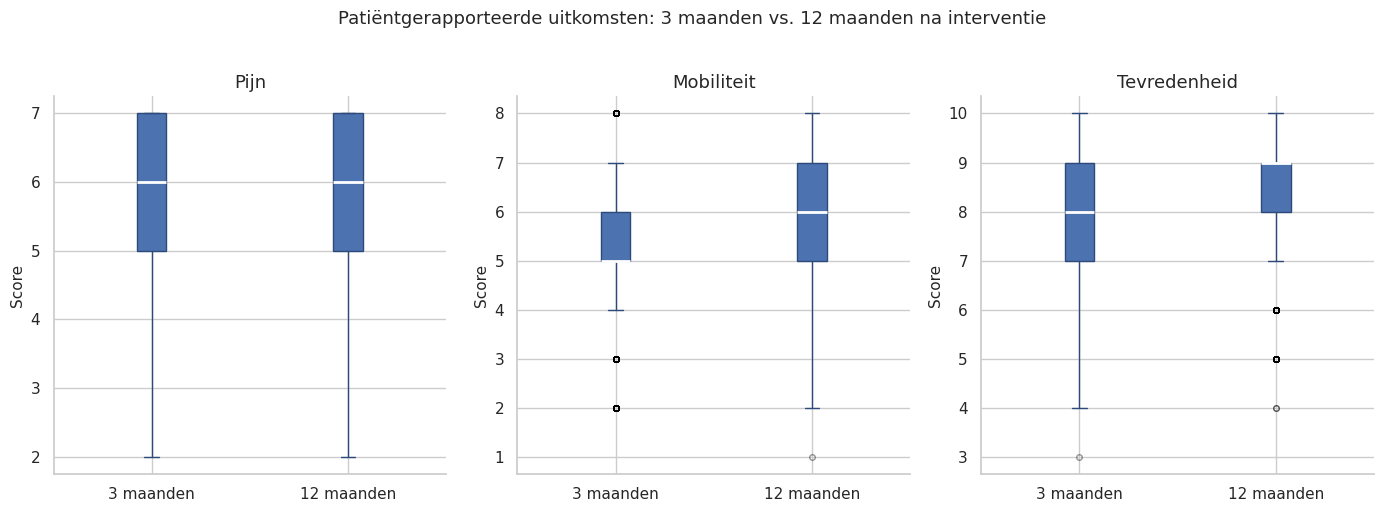

In [13]:
# ── Box plots: pijn, mobiliteit en tevredenheid (3 maanden vs. 12 maanden) ───

categorieen = [
    ("pijn_3m",         "pijn_12m",         "Pijn"),
    ("mobiliteit_3m",   "mobiliteit_12m",   "Mobiliteit"),
    ("tevredenheid_3m", "tevredenheid_12m", "Tevredenheid"),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, (col_3m, col_12m, titel) in zip(axes, categorieen):
    ax.boxplot(
        [questionnaire[col_3m].dropna(), questionnaire[col_12m].dropna()],
        tick_labels=["3 maanden", "12 maanden"],
        patch_artist=True,
        boxprops=dict(facecolor="#4C72B0", color="#2d4a7a"),
        medianprops=dict(color="white", linewidth=2),
        whiskerprops=dict(color="#2d4a7a"),
        capprops=dict(color="#2d4a7a"),
        flierprops=dict(marker="o", markersize=4, alpha=0.4),
    )
    ax.set_title(titel)
    ax.set_ylabel("Score")

plt.suptitle(
    "Patiëntgerapporteerde uitkomsten: 3 maanden vs. 12 maanden na interventie",
    fontsize=13, y=1.02,
)
plt.tight_layout()
plt.show()


## 6. IC-machinedata

De IC-machinedata (`bp3/data/machine_data/*.csv`) is alleen beschikbaar voor patiënten met een koppeling in `patient_machine_mapping.csv`. Kolommen: `TS`, `SBP` (bovendruk), `DBP` (onderdruk), `HR` (hartslag), `Fluids`, `BloodLost` en `BloodGiven`.

In [14]:
# ── Inladen en combineren van alle machine-CSV's ─────────────────────────────

machine_dfs = []
for fname in sorted(os.listdir(MACHINE_DIR)):
    if not fname.endswith(".csv"):
        continue
    df_temp = pd.read_csv(os.path.join(MACHINE_DIR, fname), parse_dates=["TS"])
    df_temp["bestand"] = fname
    machine_dfs.append(df_temp)

machine_all = pd.concat(machine_dfs, ignore_index=True)

print(f"Aantal machinebestanden : {len(machine_dfs)}")
print(f"Totaal aantal metingen  : {len(machine_all):,}")
print(f"Tijdsperiode            : {machine_all['TS'].min()} — {machine_all['TS'].max()}")

# ── Descriptieve statistieken (alle machines gecombineerd) ───────────────────
METRIC_COLS = ["SBP", "DBP", "HR", "Fluids", "BloodLost", "BloodGiven"]

stats = machine_all[METRIC_COLS].agg(["mean", "median", "std", "min", "max"])
missing = machine_all[METRIC_COLS].isnull().sum().rename("missing values")
stats_table = pd.concat([stats.T, missing], axis=1)
stats_table.columns = ["Mean", "Median", "Std. deviation", "Minimum", "Maximum", "Missing values"]

print("\n=== Geaggregeerde statistieken — alle machinedata ===")
print(stats_table.round(3).to_string())


Aantal machinebestanden : 20
Totaal aantal metingen  : 593
Tijdsperiode            : 2026-05-11 06:00:00 — 2026-05-11 12:29:00

=== Geaggregeerde statistieken — alle machinedata ===
               Mean  Median  Std. deviation  Minimum  Maximum  Missing values
SBP         120.954  118.40          24.122     90.0   175.20               0
DBP          71.949   69.40          10.878     60.0   103.60               0
HR          100.507   98.55          21.739     50.0   138.50               1
Fluids        2.344    2.18           0.870      1.0     4.72               0
BloodLost     1.767    1.55           1.084      0.0     4.98               0
BloodGiven    1.431    1.38           1.229      0.0     4.83               0


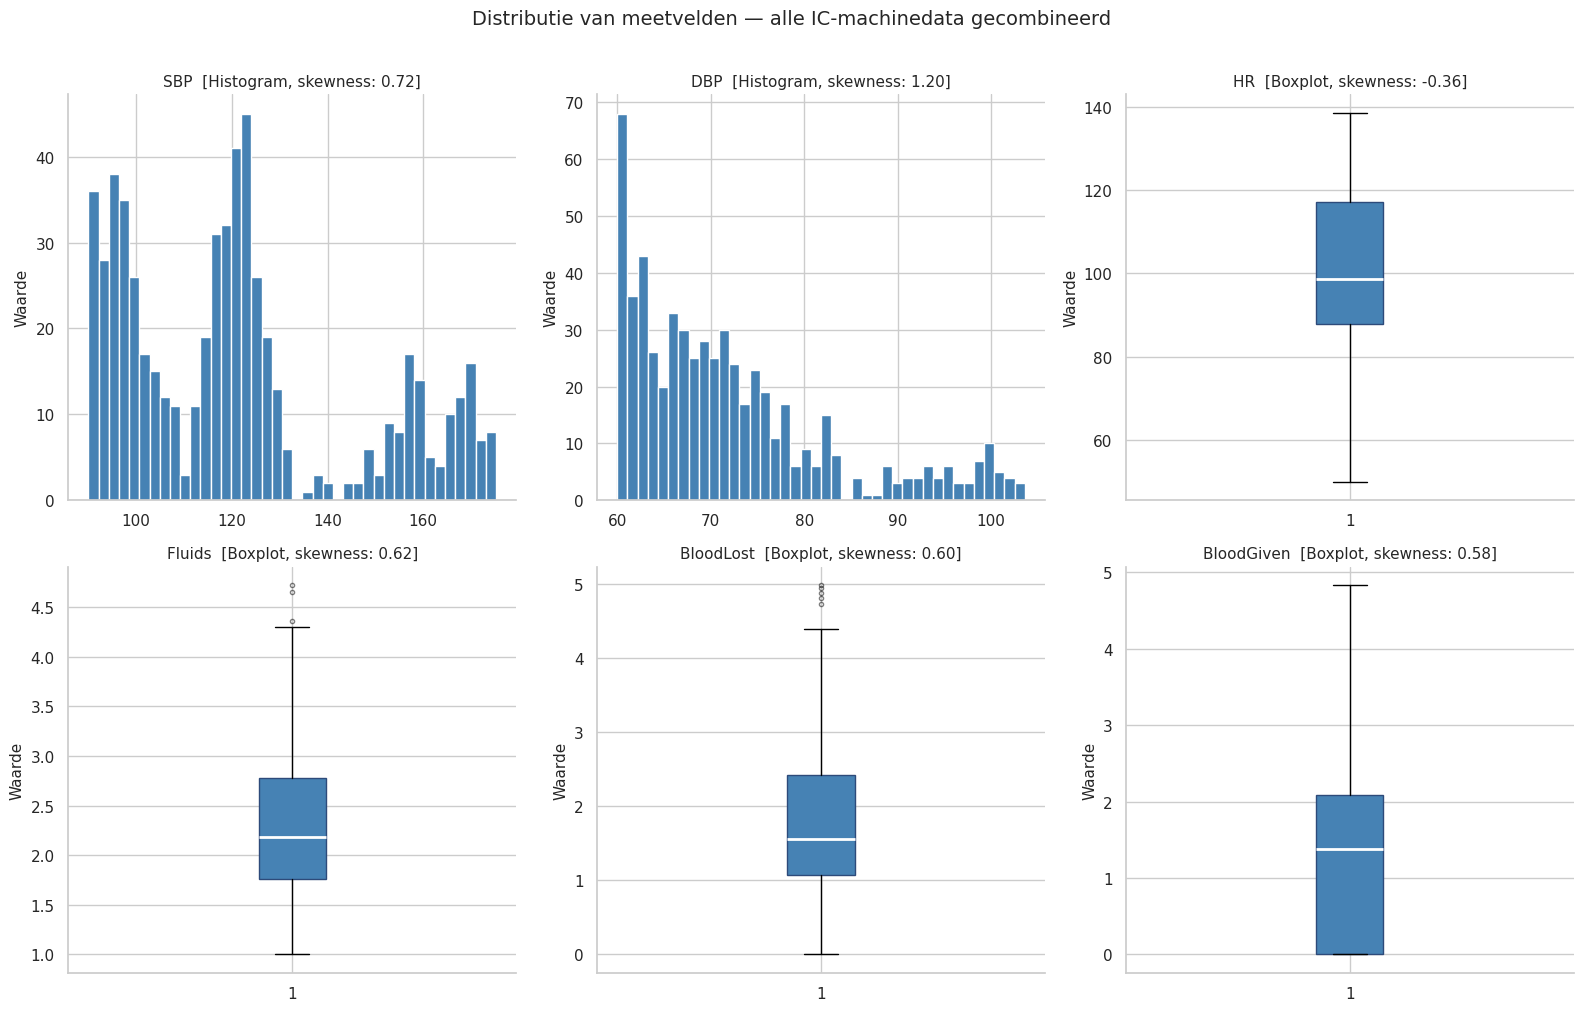

Aantal outliers per meetveld (IQR-methode, 1.5× IQR):
  SBP         :      13 outliers van 593 metingen (2.19%)
  DBP         :      37 outliers van 593 metingen (6.24%)
  HR          :       0 outliers van 592 metingen (0.00%)
  Fluids      :       3 outliers van 593 metingen (0.51%)
  BloodLost   :       5 outliers van 593 metingen (0.84%)
  BloodGiven  :       0 outliers van 593 metingen (0.00%)


In [15]:
# ── Distributie per meetveld: boxplot, of histogram bij skewness > 1.0 ───────
# SBP en DBP (bloeddruk) krijgen altijd hetzelfde grafiektype: als één van
# beide een histogram krijgt op basis van skewness, geldt dat voor beide.

skewness = machine_all[METRIC_COLS].skew()
SKEWNESS_THRESHOLD = 1.0

histogram_fields = {col for col in METRIC_COLS if abs(skewness[col]) > SKEWNESS_THRESHOLD}
if "SBP" in histogram_fields or "DBP" in histogram_fields:
    histogram_fields.update(["SBP", "DBP"])

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(METRIC_COLS):
    ax = axes[i]
    data = machine_all[col].dropna()

    if col in histogram_fields:
        ax.hist(data, bins=40, color="steelblue", edgecolor="white")
        plot_type = "Histogram"
    else:
        ax.boxplot(
            data, patch_artist=True,
            boxprops=dict(facecolor="steelblue", color="#2d4a7a"),
            medianprops=dict(color="white", linewidth=2),
            flierprops=dict(marker="o", markersize=3, alpha=0.5),
        )
        plot_type = "Boxplot"

    ax.set_title(f"{col}  [{plot_type}, skewness: {skewness[col]:.2f}]", fontsize=11)
    ax.set_ylabel("Waarde")

plt.suptitle("Distributie van meetvelden — alle IC-machinedata gecombineerd", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# ── Outlier-aantallen per meetveld (IQR-methode: buiten 1.5× IQR) ────────────
print("Aantal outliers per meetveld (IQR-methode, 1.5× IQR):")
for col in METRIC_COLS:
    data = machine_all[col].dropna()
    q1, q3 = data.quantile(0.25), data.quantile(0.75)
    iqr = q3 - q1
    ondergrens, bovengrens = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((data < ondergrens) | (data > bovengrens)).sum()
    print(f"  {col:<12}: {n_outliers:>7,} outliers van {len(data):,} metingen "
          f"({n_outliers / len(data) * 100:.2f}%)")


## 7. NZa-wachttijdendata

Deze sectie behandelt de wachttijdenvergelijking met regionale ziekenhuizen: het historische bulkbestand (`wachttijden_history.csv`), de actuele API-snapshot (`wachttijden_latest.json`), de ziekenhuizenlijst (`kvk_nummers.csv`) en de mapping EPD ↔ NZa (`treatments.csv`).

In [16]:
# ── Inladen van de NZa-wachttijdenbestanden ──────────────────────────────────

wachttijden_history = pd.read_csv(os.path.join(NZA_DIR, "wachttijden_history.csv"))

with open(os.path.join(NZA_DIR, "wachttijden_latest.json"), encoding="utf-8") as f:
    wachttijden_latest = pd.json_normalize(json.load(f))

# treatments.csv koppelt EPD-behandelnamen aan NZa-behandelnamen (puntkomma-gescheiden)
treatments_map = pd.read_csv(os.path.join(NZA_DIR, "treatments.csv"), sep=";")

kvk_nummers = pd.read_csv(os.path.join(NZA_DIR, "kvk_nummers.csv"), dtype=str)

print(f"Historisch bulkbestand : {len(wachttijden_history):,} rijen")
print(f"API-snapshot           : {len(wachttijden_latest):,} rijen")
print(f"Treatments-mapping     : {len(treatments_map)} rijen")
print(f"Ziekenhuizen (kvk_nummers.csv): {kvk_nummers['naam'].nunique()} vestigingen, "
      f"{kvk_nummers['kvk'].nunique()} unieke KvK-nummers")


Historisch bulkbestand : 26,867 rijen
API-snapshot           : 1,179 rijen
Treatments-mapping     : 91 rijen
Ziekenhuizen (kvk_nummers.csv): 15 vestigingen, 10 unieke KvK-nummers


In [17]:
# ── KPI10 / FR13: koppeling van EPD-behandelingen aan NZa-behandelnamen ──────

# Alle distincte behandelingen die daadwerkelijk in het EPD voorkomen
epd_treatments = set(eoc_treatment.merge(treatment_type, on="tid")["tname"].unique())

# Mapping filteren tot de behandelingen die ook echt in het EPD voorkomen
mapping_used = treatments_map[treatments_map["epd"].isin(epd_treatments)].copy()
mapping_used["nza"] = mapping_used["nza"].fillna("").str.strip()
gekoppeld = mapping_used[mapping_used["nza"] != ""]
niet_gekoppeld = mapping_used[mapping_used["nza"] == ""]

pct_gekoppeld = len(gekoppeld) / len(epd_treatments) * 100

print(f"Distincte behandelingen in het EPD             : {len(epd_treatments)}")
print(f"Waarvan gekoppeld aan een NZa-behandelnaam      : {len(gekoppeld)}")
print(f"Percentage gekoppeld                            : {pct_gekoppeld:.1f}%")
print("\nNiet-gekoppelde EPD-behandelingen:")
for naam in sorted(niet_gekoppeld["epd"]):
    print(f"  - {naam}")

# Radboudumc-KVK-nummer en de gekoppelde NZa-namen (gebruikt in de rest van deze sectie).
# Sommige EPD-behandelingen delen dezelfde NZa-behandelnaam (bijv. Gastroscopie),
# vandaar de deduplicatie.
RADBOUDUMC_KVK = kvk_nummers.loc[kvk_nummers["naam"].str.contains("Radboudumc"), "kvk"].iloc[0]
gekoppelde_nza_namen = sorted(gekoppeld["nza"].unique())

print(f"\nAantal gekoppelde behandelingen (uniek op NZa-naam): {len(gekoppelde_nza_namen)}")
for naam in gekoppelde_nza_namen:
    print(f"  - {naam}")


Distincte behandelingen in het EPD             : 35
Waarvan gekoppeld aan een NZa-behandelnaam      : 10
Percentage gekoppeld                            : 28.6%

Niet-gekoppelde EPD-behandelingen:
  - ARDS ventilatory support (COVID-19 pneumonia)
  - Appendectomy
  - Bacterial meningitis management
  - Burn wound management
  - Caesarean section
  - Cardiogenic shock / multi-organ failure management
  - Community-acquired pneumonia (ward-based treatment)
  - Diabetic ketoacidosis management
  - Emergency laparotomy (perforated peptic ulcer)
  - Fracture fixation (orthopaedic trauma)
  - Hypertensive emergency management
  - Ischaemic stroke thrombolysis
  - Liver transplantation
  - Opioid overdose management
  - Pneumonia / respiratory failure management
  - Pulmonary embolism thrombolysis
  - Renal replacement therapy (CVVH)
  - Sepsis management (laparotomy - Hartmann procedure)
  - Severe acute pancreatitis management
  - Thoracic surgery (lobectomy)
  - Traumatic brain injury mana

In [18]:
# ── Verdeling van de gekoppelde behandelingen over TreatmentType en Specialism ─
# Dit zijn de dimensies waarop het dashboard filterbaar moet zijn (FR11).
mapped_latest = wachttijden_latest[wachttijden_latest["Treatment"].isin(gekoppeld["nza"])]
verdeling = (
    mapped_latest[["Treatment", "TreatmentType", "Specialism"]]
    .drop_duplicates()
    .sort_values(["TreatmentType", "Specialism"])
)
print("TreatmentType / Specialism van de gekoppelde behandelingen:")
print(verdeling.to_string(index=False))

# ── Dekking van de ziekenhuizen uit kvk_nummers.csv in de twee wachttijdbronnen ─
kvk_set = set(kvk_nummers["kvk"].astype(int))
latest_kvks = set(wachttijden_latest["KVKNumber"].astype(int))
history_kvks = set(wachttijden_history["KVK_INSTELLING"].astype(int))

ontbreekt_in_latest = kvk_set - latest_kvks
ontbreekt_in_history = kvk_set - history_kvks
print(f"\nZiekenhuizen in kvk_nummers.csv: {len(kvk_set)}")
print(f"  Ontbrekend in wachttijden_latest.json: {ontbreekt_in_latest or 'geen'}")
print(f"  Ontbrekend in wachttijden_history.csv: {ontbreekt_in_history or 'geen'}")

# ── AllCareproviders: constant of variabel? ──────────────────────────────────
unieke_waarden = wachttijden_latest["AllCareproviders"].unique()
print(f"\nAllCareproviders (ongedocumenteerd veld) — unieke waarden in de snapshot: {unieke_waarden}")
if len(unieke_waarden) == 1:
    print("Het veld is constant in deze snapshot en draagt hier geen informatie bij.")


TreatmentType / Specialism van de gekoppelde behandelingen:
                                                                              Treatment TreatmentType                       Specialism
                                                       Hartkatheterisatie (cardiologie)   Behandeling                Cardiologie (320)
                                                        Dotterbehandeling (cardiologie)   Behandeling                Cardiologie (320)
Aortocoronaire bypass-operatie als zelfstandige verrichting (cardiopulmonale chirurgie)   Behandeling  Cardiopulmonale chirurgie (328)
                                                       Galblaasverwijdering (heelkunde)   Behandeling      Chirurgie (heelkunde) (303)
     Operatieve behandeling liesbreuk (hernia inguinalis/ hernia femoralis) (heelkunde)   Behandeling      Chirurgie (heelkunde) (303)
                                                  Tonsillectomie en/of adenotomie (kno)   Behandeling                        KNO (

### Historische wachttijd per behandeling (Radboudumc)

Box plots van de wachttijd (dagen) per gekoppelde behandeling, op basis van de historische metingen in `wachttijden_history.csv`. Alleen de metingen van het eigen ziekenhuis (Radboudumc) worden getoond; rijen met `INSUFFICIENT_OBSERVATIONS` hebben geen `WACHTTIJD`-waarde en vallen daardoor vanzelf buiten de box plots.

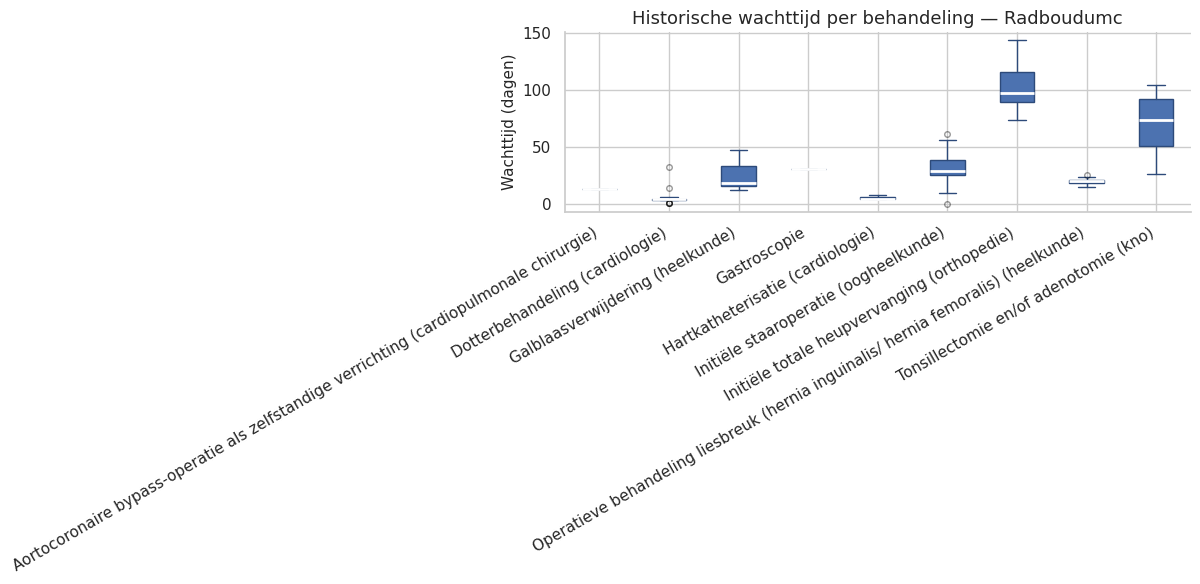

In [19]:
# ── 10.1: box plots wachttijd (dagen) per behandeling — Radboudumc, historisch ─

# KVK_INSTELLING in wachttijden_history.csv is numeriek; kvk_nummers.csv is tekst
radboudumc_history = wachttijden_history[
    (wachttijden_history["KVK_INSTELLING"] == int(RADBOUDUMC_KVK))
    & (wachttijden_history["OMS_WACHTTIJD"].isin(gekoppelde_nza_namen))
]

fig, ax = plt.subplots(figsize=(12, 6))
data_per_behandeling = [
    radboudumc_history.loc[radboudumc_history["OMS_WACHTTIJD"] == behandeling, "WACHTTIJD"].dropna()
    for behandeling in gekoppelde_nza_namen
]
ax.boxplot(
    data_per_behandeling,
    tick_labels=gekoppelde_nza_namen,
    patch_artist=True,
    boxprops=dict(facecolor="#4C72B0", color="#2d4a7a"),
    medianprops=dict(color="white", linewidth=2),
    whiskerprops=dict(color="#2d4a7a"),
    capprops=dict(color="#2d4a7a"),
    flierprops=dict(marker="o", markersize=4, alpha=0.4),
)
ax.set_title("Historische wachttijd per behandeling — Radboudumc")
ax.set_ylabel("Wachttijd (dagen)")
ax.tick_params(axis="x", rotation=30)
for label in ax.get_xticklabels():
    label.set_ha("right")
plt.tight_layout()
plt.show()


### Ontwikkeling van de wachttijd over tijd (Radboudumc, FR12)

Per behandeling de wachttijd (dagen) over tijd, op basis van de `PEILDATUM`-metingen in `wachttijden_history.csv` voor Radboudumc. Metingen met `INSUFFICIENT_OBSERVATIONS` hebben geen `WACHTTIJD`-waarde; deze gaten worden zichtbaar gelaten in plaats van opgevuld (FR12). Een lijn wordt alleen getoond voor behandelingen met voldoende niet-ontbrekende metingen om een ontwikkeling te kunnen laten zien.

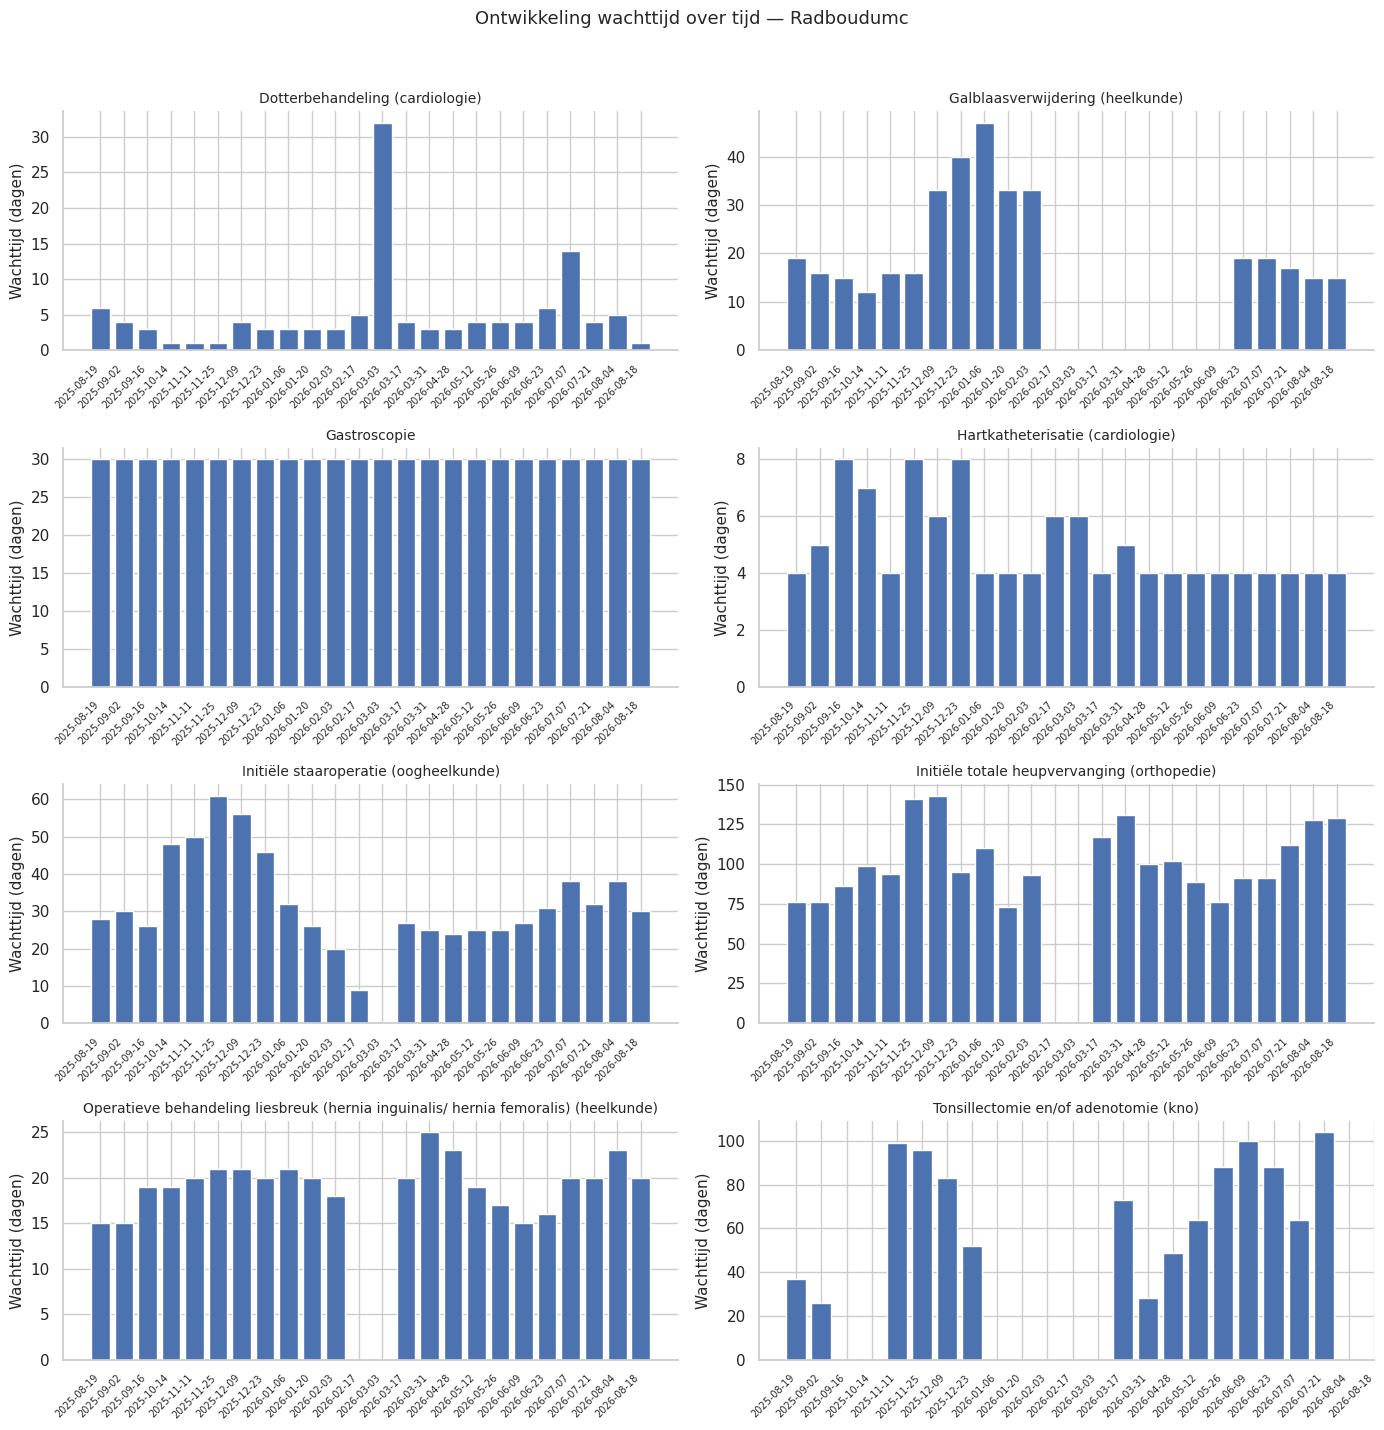

Geen ontwikkeling getoond voor 1 behandeling(en) met minder dan 3 niet-ontbrekende metingen bij Radboudumc:
  - Aortocoronaire bypass-operatie als zelfstandige verrichting (cardiopulmonale chirurgie) (1 meting(en))


In [20]:
# ── 10.2: ontwikkeling wachttijd over tijd per behandeling — Radboudumc ──────

MIN_METINGEN = 3  # minimum aantal niet-ontbrekende metingen om een ontwikkeling te tonen

radboudumc_history["peildatum"] = pd.to_datetime(radboudumc_history["PEILDATUM"])

# Per behandeling: aantal niet-ontbrekende wachttijd-metingen bepalen
aantal_metingen = radboudumc_history.groupby("OMS_WACHTTIJD")["WACHTTIJD"].count()
te_tonen = [b for b in gekoppelde_nza_namen if aantal_metingen.get(b, 0) >= MIN_METINGEN]
overgeslagen = [b for b in gekoppelde_nza_namen if b not in te_tonen]

n_kolommen = 2
n_rijen = -(-len(te_tonen) // n_kolommen)  # ceil-deling
fig, axes = plt.subplots(n_rijen, n_kolommen, figsize=(14, 3.5 * n_rijen))
axes = np.atleast_1d(axes).flatten()

for ax, behandeling in zip(axes, te_tonen):
    reeks = (
        radboudumc_history[radboudumc_history["OMS_WACHTTIJD"] == behandeling]
        .sort_values("peildatum")
    )
    # Discrete meetmomenten -> staafdiagram in plaats van lijngrafiek. NaN-waarden
    # (onvoldoende data op dat meetmoment) niet opvullen: de balk ontbreekt gewoon.
    ax.bar(range(len(reeks)), reeks["WACHTTIJD"], color="#4C72B0", edgecolor="white")
    ax.set_xticks(range(len(reeks)))
    ax.set_xticklabels(reeks["peildatum"].dt.strftime("%Y-%m-%d"), rotation=45, ha="right", fontsize=7)
    ax.set_title(behandeling, fontsize=10)
    ax.set_ylabel("Wachttijd (dagen)")

for ax in axes[len(te_tonen):]:
    ax.set_visible(False)

fig.suptitle("Ontwikkeling wachttijd over tijd — Radboudumc", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

print(f"Geen ontwikkeling getoond voor {len(overgeslagen)} behandeling(en) met minder dan "
      f"{MIN_METINGEN} niet-ontbrekende metingen bij Radboudumc:")
for naam in overgeslagen:
    print(f"  - {naam} ({aantal_metingen.get(naam, 0)} meting(en))")


### Actuele wachttijd Radboudumc vs. regionale ziekenhuizen (FR11)

In [21]:
# ── FR11: wachttijd eigen ziekenhuis (Radboudumc) vs. regio, per behandeling ─

# InsufficientObservations ('Ja'/'Nee') omzetten naar boolean
wl = wachttijden_latest.copy()
wl["onvoldoende_data"] = wl["InsufficientObservations"] == "Ja"

subset = wl[wl["Treatment"].isin(gekoppelde_nza_namen)].copy()

# Per KVK-nummer en behandeling: gemiddelde wachttijd over de vestigingen met
# voldoende data; als GEEN enkele vestiging voldoende data heeft, dan
# 'onvoldoende data' voor het hele ziekenhuis bij die behandeling.
def aggregeer(groep: pd.DataFrame) -> pd.Series:
    voldoende = groep[~groep["onvoldoende_data"]]
    if voldoende.empty:
        return pd.Series({"wachttijd": np.nan, "onvoldoende_data": True})
    return pd.Series({"wachttijd": voldoende["WaitingTime"].mean(), "onvoldoende_data": False})

per_ziekenhuis = (
    subset.groupby(["KVKNumber", "CareProvider", "Treatment"])
    .apply(aggregeer, include_groups=False)
    .reset_index()
)

# Ziekenhuisnamen inkorten voor leesbare labels op de X-as
per_ziekenhuis["label"] = np.where(
    per_ziekenhuis["KVKNumber"] == RADBOUDUMC_KVK,
    "Radboudumc (eigen ziekenhuis)",
    per_ziekenhuis["CareProvider"],
)


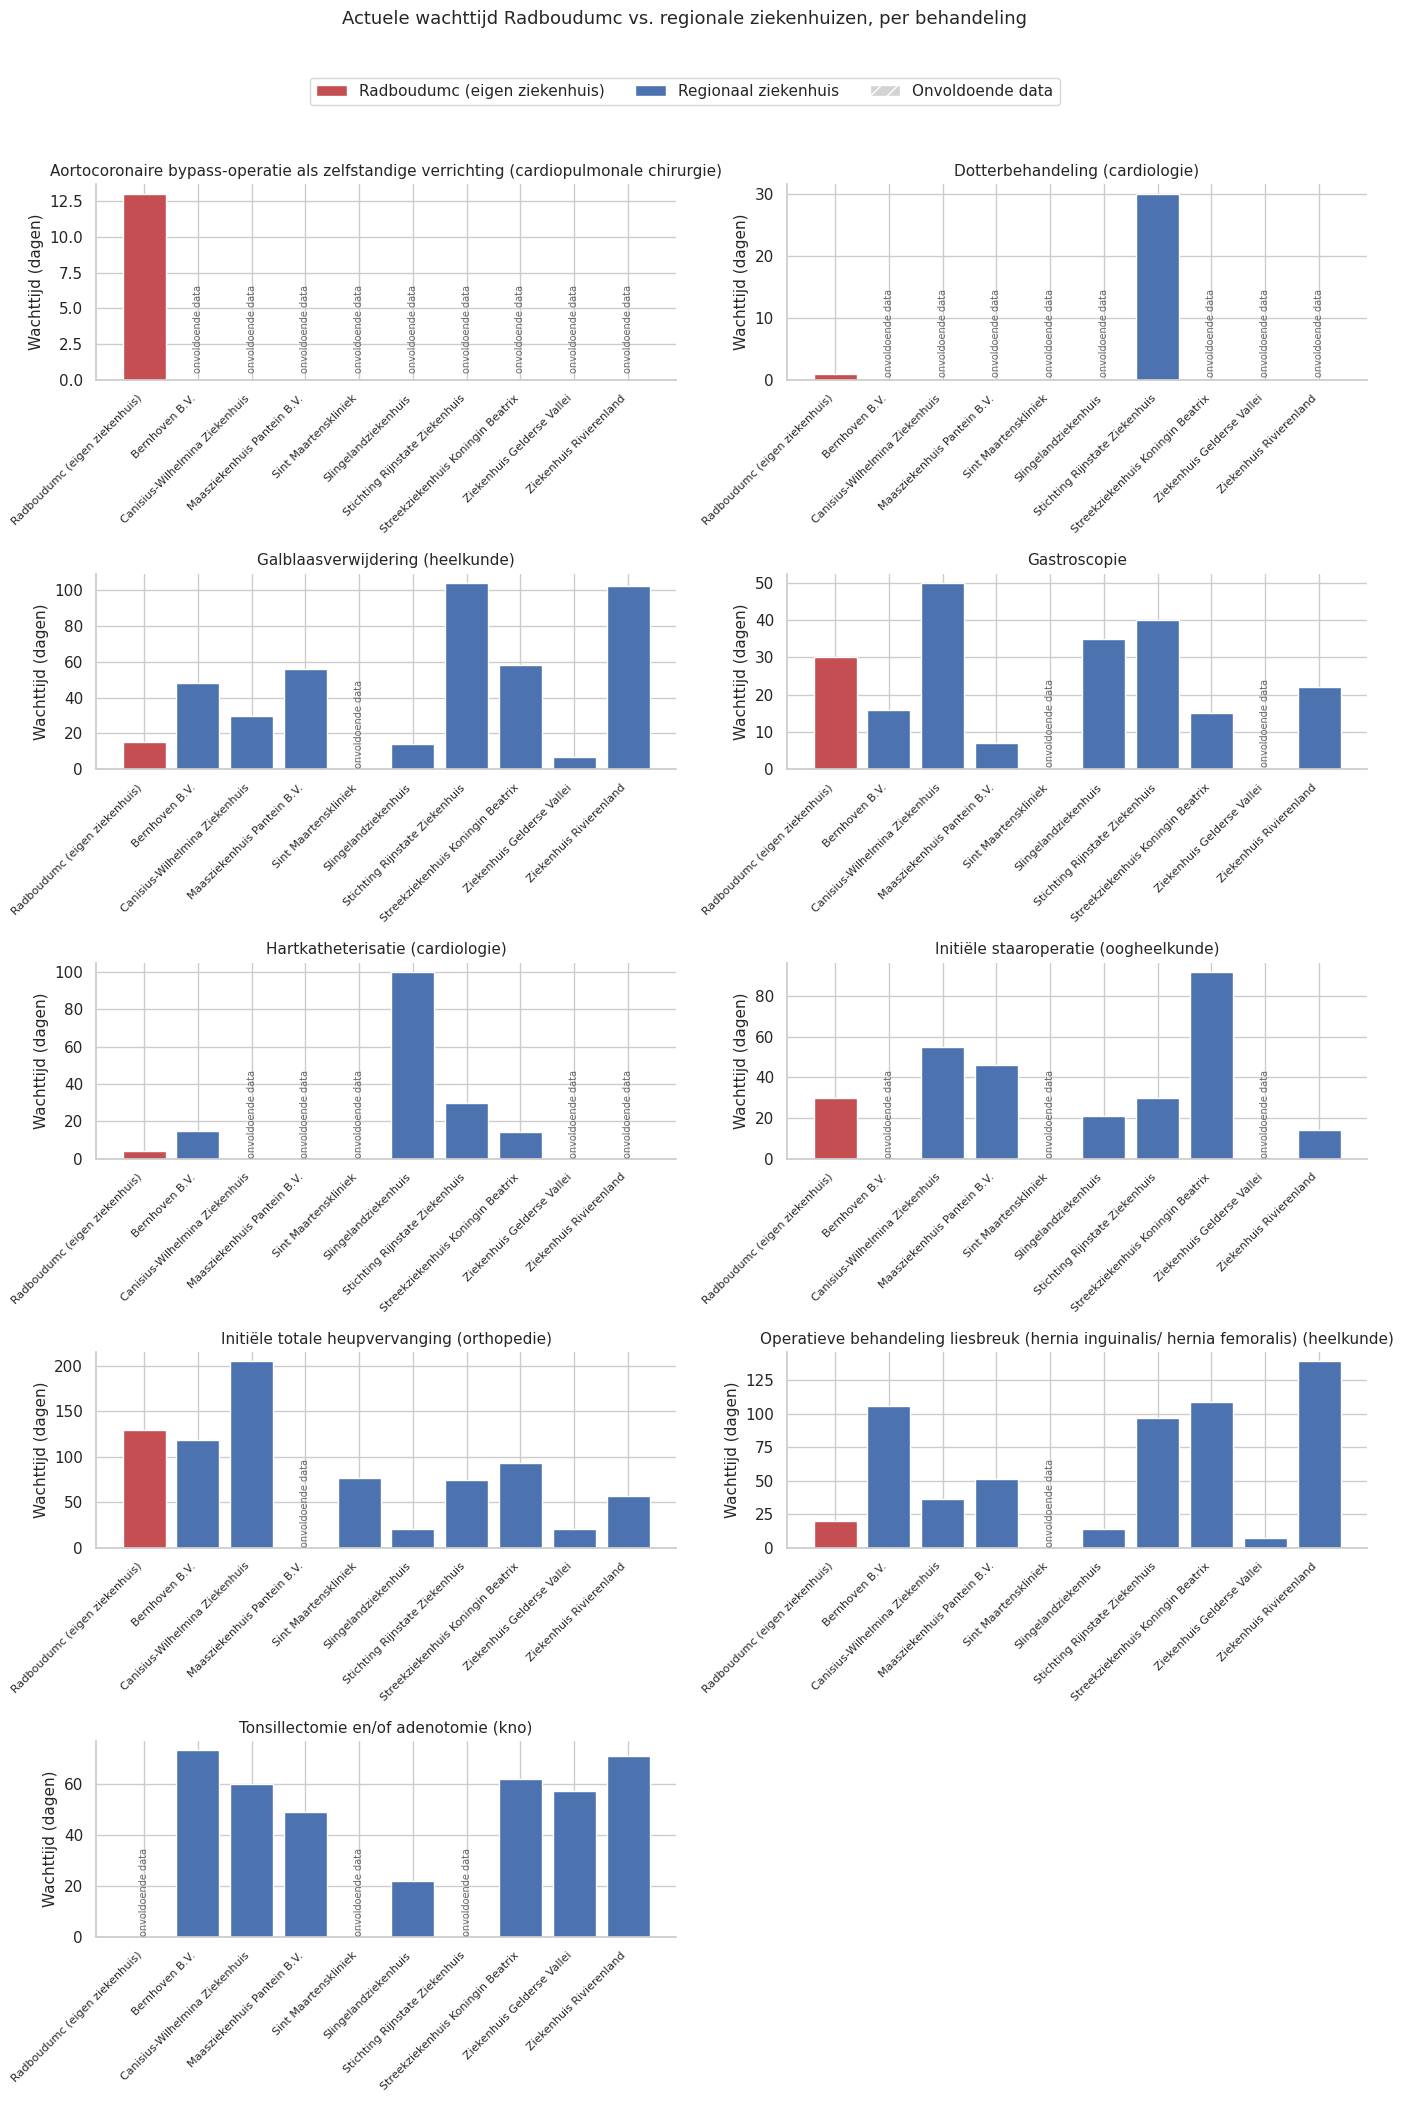

In [22]:
# ── Aparte staafdiagrammen: wachttijd Radboudumc vs. regionale ziekenhuizen, per behandeling ─

ziekenhuizen = per_ziekenhuis["label"].unique().tolist()
# Radboudumc als eerste, ter herkenbaarheid
ziekenhuizen.sort(key=lambda naam: (naam != "Radboudumc (eigen ziekenhuis)", naam))

n_behandelingen = len(gekoppelde_nza_namen)
n_kolommen = 2
n_rijen = -(-n_behandelingen // n_kolommen)  # ceil-deling

fig, axes = plt.subplots(n_rijen, n_kolommen, figsize=(14, 4 * n_rijen))
axes = axes.flatten()

for ax, behandeling in zip(axes, gekoppelde_nza_namen):
    waarden = []
    onvoldoende = []
    for ziekenhuis in ziekenhuizen:
        rij = per_ziekenhuis[
            (per_ziekenhuis["label"] == ziekenhuis) & (per_ziekenhuis["Treatment"] == behandeling)
        ]
        if rij.empty or rij["onvoldoende_data"].iloc[0]:
            waarden.append(0)
            onvoldoende.append(True)
        else:
            waarden.append(rij["wachttijd"].iloc[0])
            onvoldoende.append(False)

    kleuren = ["#C44E52" if z.startswith("Radboudumc") else "#4C72B0" for z in ziekenhuizen]
    bars = ax.bar(range(len(ziekenhuizen)), waarden, color=kleuren, edgecolor="white")

    # Markeer ziekenhuizen met onvoldoende data duidelijk (kruisarcering + label)
    for rect, onv in zip(bars, onvoldoende):
        if onv:
            rect.set_hatch("//")
            rect.set_facecolor("lightgray")
            ax.text(rect.get_x() + rect.get_width() / 2, 0.5, "onvoldoende data",
                    ha="center", va="bottom", fontsize=7, rotation=90, color="dimgray")

    ax.set_xticks(range(len(ziekenhuizen)))
    ax.set_xticklabels(ziekenhuizen, rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("Wachttijd (dagen)")
    ax.set_title(behandeling, fontsize=11)

# Ongebruikte subplots (als n_behandelingen oneven is) verbergen
for ax in axes[n_behandelingen:]:
    ax.set_visible(False)

# Compacte, gedeelde legenda: alleen eigen ziekenhuis vs. regio, en de onvoldoende-data-markering
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#C44E52", label="Radboudumc (eigen ziekenhuis)"),
    Patch(facecolor="#4C72B0", label="Regionaal ziekenhuis"),
    Patch(facecolor="lightgray", hatch="//", label="Onvoldoende data"),
]
fig.legend(handles=legend_elements, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))

fig.suptitle("Actuele wachttijd Radboudumc vs. regionale ziekenhuizen, per behandeling", y=1.05, fontsize=13)
plt.tight_layout()
plt.show()


In [23]:
# ── FR12: sluiten de kolommen van wachttijden_history.csv aan bij de API-velden? ─

print("Kolommen wachttijden_history.csv:")
for kol in wachttijden_history.columns:
    print(f"  - {kol}")

print(f"\nVelden wachttijden_latest.json ({len(wachttijden_latest.columns)}):")
for kol in wachttijden_latest.columns:
    print(f"  - {kol}")

print(f"\nAantal kolommen history: {wachttijden_history.shape[1]}, "
      f"aantal velden API: {wachttijden_latest.shape[1]}")


Kolommen wachttijden_history.csv:
  - ID
  - NAAM_VESTIGING
  - KVK_VESTIGING_NR
  - TYPE_WACHTTIJD
  - CODE_WACHTTIJD
  - WACHTTIJD
  - OMS_WACHTTIJD
  - SPECIALISME
  - LOCATIECODE
  - AGBCODE
  - STRAAT
  - POSTCODE
  - PLAATS
  - ROAZ_REGIO
  - NAAM_INSTELLING
  - TYPE_ZORGINSTELLING
  - DATUM_ZORGBEELD
  - WEEK_DAGEN
  - JAARMAAND
  - PEILDATUM
  - INSUFFICIENT_OBSERVATIONS
  - KVK_INSTELLING

Velden wachttijden_latest.json (21):
  - Date
  - InsufficientObservations
  - KVKNumber
  - CareProvider
  - CareProvider_AGBCode
  - LocationKey
  - KVKLocationNumber
  - Location_AGBCode
  - Location
  - Street
  - StreetNumber
  - PostalCode
  - City
  - TreatmentKey
  - TreatmentNumber
  - Treatment
  - TreatmentType
  - Specialism
  - Description
  - AllCareproviders
  - WaitingTime

Aantal kolommen history: 22, aantal velden API: 21


**Conclusie — geen één-op-één aansluiting tussen `wachttijden_history.csv` en de API-velden.** Dit is relevant voor FR12: het combineren van het historische bestand met periodieke API-snapshots vergt eerst een mapping-slag, geen simpele concat.

Concrete discrepanties:
- **Andere naamgeving en taal**: de historische kolommen zijn Nederlandse, hoofdlettergevoelige namen (`WACHTTIJD`, `SPECIALISME`, `NAAM_INSTELLING`), de API-velden zijn Engelse `PascalCase`-namen (`WaitingTime`, `Specialism`, `CareProvider`). Er is geen directe 1-op-1 kolomnaam-match.
- **Sleutels verschillen**: de API identificeert een vestiging via `KVKLocationNumber` (zonder voorloopnullen, bijv. `"80262783"`) en een behandeling via een GUID (`TreatmentKey`); het historische bestand gebruikt `KVK_VESTIGING_NR` (met voorloopnullen, bijv. `"000080262783"`) en een numerieke `CODE_WACHTTIJD`/GUID-achtige sleutel. Het aansluiten van deze sleutels op elkaar (en op `kvk_nummers.csv`, dat `vestigingsnummer` met voorloopnullen gebruikt) is een niet-triviale reconciliatie die hier bewust buiten scope blijft.
- **`InsufficientObservations`-codering verschilt**: in de API is dit een `"Ja"`/`"Nee"`-tekstveld, in het historische bestand heet de kolom `INSUFFICIENT_OBSERVATIONS` en bevat deze `TRUE`/`FALSE`-waarden.
- **Extra velden in de API die in history ontbreken**: `AllCareproviders` (ongedocumenteerd), `LocationKey`/`TreatmentKey` (portal-GUID's), `Description` (vrije tekst met zorgactiviteitencodes).
- **Extra velden in history die in de API ontbreken**: `ROAZ_REGIO`, `WEEK_DAGEN`, `JAARMAAND`, `PEILDATUM`, `DATUM_ZORGBEELD`, `TYPE_ZORGINSTELLING` — contextvelden van de landelijke NZa-export die de per-vestiging API-respons niet meegeeft.
- **Momentopname vs. periode**: de API geeft `Date` (het exacte moment van opvragen), terwijl history `JAARMAAND`/`PEILDATUM` gebruikt (een periode-aanduiding). Voor een tijdreeks (FR12) moet dit onderscheid expliciet gemaakt worden.

Voor FR12 betekent dit dat een combinatie van `wachttijden_history.csv` en opeenvolgende API-snapshots een aparte mapping- en normalisatiestap vereist (kolomnamen, sleutels én coderingen), vergelijkbaar met de KVKLocationNumber/vestigingsnummer-mismatch die elders in deze repository bewust als open probleem is achtergelaten.